<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/07_cLab_TcEstudiante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Laboratorio — Determinación de la temperatura crítica del modelo de Ising 2D con redes neuronales de *scikit-learn*

**Maestría en Computación Científica · Módulo de Redes Neuronales · Modelo de Ising 2D**

En este laboratorio vas a **entrenar una red neuronal clasificadora con `scikit-learn`** y a
usarla como un *termómetro* para localizar la **temperatura crítica** $T_c$ de la transición
de fase ferromagnética del modelo de Ising en 2D.



## Objetivos de aprendizaje

Al terminar este laboratorio serás capaz de:

1. Entrenar un clasificador de red neuronal con `sklearn.neural_network.MLPClassifier`,
   identificando el papel de cada hiperparámetro.
2. **Contrastar la API de `scikit-learn` 
3. Usar un clasificador entrenado **lejos** de la transición para estimar la fase
   (ordenada / desordenada) a temperaturas **cercanas** a $T_c$.
4. Estimar $T_c$ a partir del cruce $\langle P(y{=}1\mid X)\rangle = 0.5$, cuantificar su
   incertidumbre entre realizaciones y compararla con el valor exacto de Onsager.

## 1. Física: transición de fase del modelo de Ising 2D

El modelo de Ising 2D en una red $L\times L$ con acoplamiento ferromagnético $J>0$ tiene energía

$$E(\{s\}) = -J \sum_{\langle i,j\rangle} s_i\, s_j, \qquad s_i \in \{-1, +1\},$$

donde la suma es sobre pares de primeros vecinos. En unidades $J = k_B = 1$, el sistema infinito
presenta una transición de fase de segundo orden a la **temperatura crítica de Onsager**

$$T_c = \frac{2}{\ln\!\left(1+\sqrt{2}\right)} \approx 2.269.$$

- $T < T_c$: **fase ordenada** (ferromagnética), magnetización por sitio $|m|$ grande.
- $T > T_c$: **fase desordenada** (paramagnética), $|m|\approx 0$.

**Idea del laboratorio** (Carrasquilla & Melko, *Nature Physics* **13**, 431 (2017)): un
clasificador entrenado solo con configuraciones *claramente* ordenadas ($y=0$) y *claramente*
desordenadas ($y=1$) aprende una frontera de decisión que, evaluada en configuraciones cercanas
a $T_c$, se comporta como un **parámetro de orden efectivo**. La temperatura donde
$\langle P(y{=}1\mid X)\rangle = 0.5$ estima $T_c$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier

RNG = 42
np.random.seed(RNG)

## 3. Datos: configuraciones lejos de $T_c$

`ising_dataset.npz` contiene configuraciones de espines de una red $16\times 16$ con frontera
periódica, generadas por Monte Carlo (Metrópolis). Campos:

| Campo | Forma | Significado |
|---|---|---|
| `X` | `(1600, 16, 16)` | Configuraciones de espines $s_i \in \{-1,+1\}$ |
| `y` | `(1600,)` | Etiqueta de fase: `0` = ordenada ($T$ baja), `1` = desordenada ($T$ alta) |
| `T` | `(1600,)` | Temperatura de cada configuración |
| `m` | `(1600,)` | Magnetización por sitio $|m|$ |
| `realizacion` | `(1600,)` | Índice de cadena Monte Carlo independiente (`0..3`) |
| `Tc`, `L`, `frontera` | escalares | Metadatos ($T_c$ exacto, tamaño, tipo de frontera) |

Las temperaturas de entrenamiento **evitan** la región crítica: hay un hueco entre
$T=1.9$ y $T=2.6$.

In [2]:
datos = np.load("Datos/ising_dataset.npz", allow_pickle=False)
X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]

Tc_exacto = float(datos["Tc"])
L = int(datos["L"])

print("X:", X.shape, X.dtype)
print("y:", y.shape, "->", np.unique(y, return_counts=True))
print("realizaciones:", np.unique(realizacion))
print("Tc exacto (Onsager):", Tc_exacto)

X: (1600, 16, 16) int8
y: (1600,) -> (array([0, 1], dtype=int8), array([800, 800]))
realizaciones: [0 1 2 3]
Tc exacto (Onsager): 2.269185314213022


### Ejercicio 1 — Exploración

Responde con código y en una celda de texto:

1. ¿Qué temperaturas tienen etiqueta `y = 0` y cuáles `y = 1`? ¿Dónde está el "hueco"?
2. ¿Está balanceado el problema (cuántas configuraciones por clase)?
3. Grafica el histograma de $|m|$ separando por clase. ¿Se separan bien las dos fases?

Temperaturas con y = 0 (ordenada):    [1.2   1.375 1.55  1.725 1.9  ]  configs por T: [160 160 160 160 160]
Temperaturas con y = 1 (desordenada): [2.6   2.825 3.05  3.275 3.5  ]  configs por T: [160 160 160 160 160]
Hueco sin datos: entre T = 1.9 y T = 2.6  (Tc = 2.269 queda adentro)
Configuraciones por clase: {np.int8(0): np.int64(800), np.int8(1): np.int64(800)}


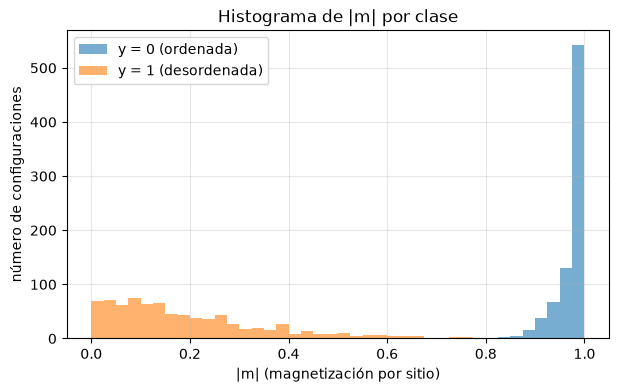

|m| clase 0: min=0.812  media=0.975
|m| clase 1: max=0.805  media=0.191


In [3]:
# --- Ejercicio 1  ---
T0, n0 = np.unique(T[y == 0], return_counts=True)
T1, n1 = np.unique(T[y == 1], return_counts=True)
print("Temperaturas con y = 0 (ordenada):   ", T0, " configs por T:", n0)
print("Temperaturas con y = 1 (desordenada):", T1, " configs por T:", n1)
print(f"Hueco sin datos: entre T = {T0.max()} y T = {T1.min()}  (Tc = {Tc_exacto:.3f} queda adentro)")
print("Configuraciones por clase:", dict(zip(*np.unique(y, return_counts=True))))

plt.figure(figsize=(7, 4))
bins = np.linspace(0, 1, 41)
plt.hist(m[y == 0], bins=bins, alpha=0.6, label="y = 0 (ordenada)")
plt.hist(m[y == 1], bins=bins, alpha=0.6, label="y = 1 (desordenada)")
plt.xlabel("|m| (magnetización por sitio)")
plt.ylabel("número de configuraciones")
plt.title("Histograma de |m| por clase")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"|m| clase 0: min={m[y==0].min():.3f}  media={m[y==0].mean():.3f}")
print(f"|m| clase 1: max={m[y==1].max():.3f}  media={m[y==1].mean():.3f}")


**Respuestas — Ejercicio 1**

1. La clase `y = 0` (ordenada) son las 5 temperaturas bajas $T \in \{1.2,\,1.375,\,1.55,\,1.725,\,1.9\}$ y la clase `y = 1` (desordenada) las 5 altas $T \in \{2.6,\,2.825,\,3.05,\,3.275,\,3.5\}$. El **hueco** va de $T=1.9$ a $T=2.6$, justo alrededor de $T_c \approx 2.269$: el modelo nunca ve configuraciones de la región crítica.
2. Sí está balanceado: 800 configuraciones por clase (160 por temperatura).
3. Sí. Los histogramas casi no se solapan: las configuraciones ordenadas tienen $|m|$ cercano a 1 y las desordenadas $|m|$ cercano a 0. Lejos de $T_c$ la magnetización sola ya separa las fases, por eso la tarea es fácil para la red.


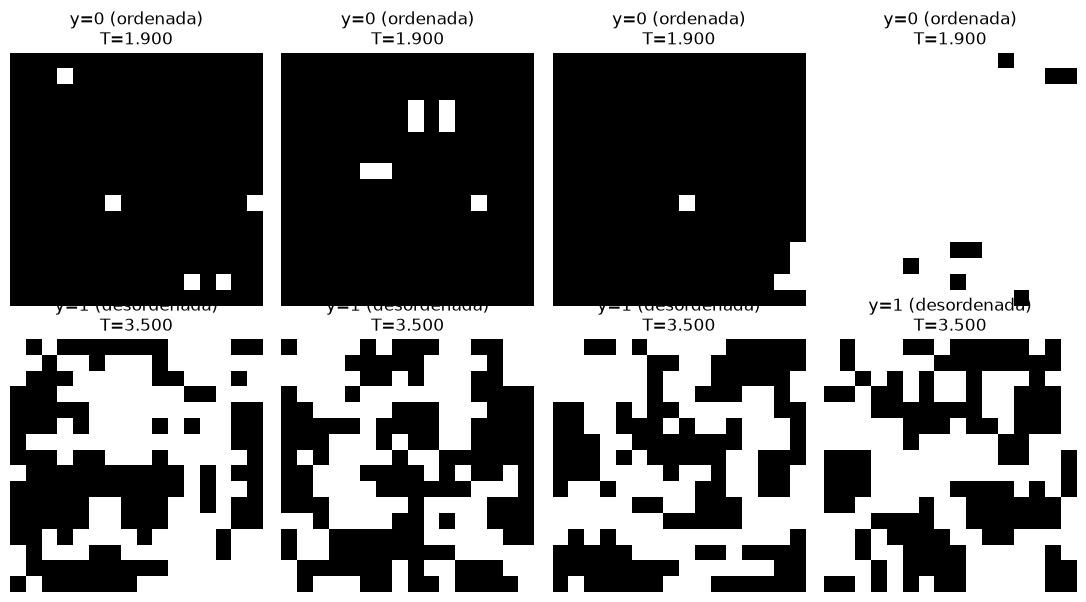

In [4]:
# Configuraciones típicas a T baja y T alta
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for row, (cls, titulo) in enumerate([(0, "ordenada"), (1, "desordenada")]):
    idx = np.where(y == cls)[0][:4]
    for k, i in enumerate(idx):
        axes[row, k].imshow(X[i], cmap="gray", vmin=-1, vmax=1)
        axes[row, k].set_title(f"y={cls} ({titulo})\nT={T[i]:.3f}")
        axes[row, k].axis("off")
plt.tight_layout()
plt.show()

## 4. Partición de los datos: por **realización**

Las configuraciones de una misma cadena Monte Carlo (`realizacion`) están **correlacionadas**
temporalmente. Si mezcláramos al azar, configuraciones casi idénticas caerían en *train* y en
*test* a la vez → fuga de información y métricas infladas.

Partimos por realización:

- **Entrenamiento:** realizaciones `0` y `1`
- **Validación:** realización `2`
- **Prueba:** realización `3`

Además aplanamos cada configuración $16\times16 \to 256$ porque `MLPClassifier` espera
vectores de características.

### Ejercicio 2 — Construir los conjuntos

Completa las máscaras y los arreglos aplanados. Deberías obtener
`X_train (800, 256)`, `X_val (400, 256)` y `X_test (400, 256)`.

In [5]:
# --- Ejercicio 2  ---
mask_train = np.isin(realizacion, [0, 1])
mask_val   = realizacion == 2
mask_test  = realizacion == 3

def aplanar(A):
    return A.reshape(A.shape[0], L * L)

X_train, y_train, T_train = aplanar(X[mask_train]), y[mask_train], T[mask_train]
X_val,   y_val,   T_val   = aplanar(X[mask_val]),   y[mask_val],   T[mask_val]
X_test,  y_test,  T_test  = aplanar(X[mask_test]),  y[mask_test],  T[mask_test]

for nombre, Xs, ys in [("train", X_train, y_train),
                       ("val",   X_val,   y_val),
                       ("test",  X_test,  y_test)]:
    print(f"{nombre:5s}  X={Xs.shape}  y={ys.shape}  clases={np.bincount(ys)}")

train  X=(800, 256)  y=(800,)  clases=[400 400]
val    X=(400, 256)  y=(400,)  clases=[200 200]
test   X=(400, 256)  y=(400,)  clases=[200 200]


## 5. Entrenar el `MLPClassifier`

| Argumento | Valor | Qué controla |
|---|---|---|
| `hidden_layer_sizes=(16, 8, 4)` | 3 capas ocultas | Arquitectura: 256 → 16 → 8 → 4 → 2 |
| `activation="relu"` | ReLU | No linealidad de las capas ocultas |
| `solver="adam"` | Adam | Optimizador basado en gradiente estocástico |
| `learning_rate_init=0.001` | 0.001 | Tamaño de paso inicial |
| `max_iter=1000` | 1000 | Máximo de épocas (puede parar antes por tolerancia) |
| `random_state=42` | 42 | Reproducibilidad (init de pesos y *shuffling*) |

> La capa de salida (2 neuronas, *softmax*) y la pérdida (*log-loss*) las añade `scikit-learn`
> automáticamente al ver que `y` tiene dos clases enteras. En `NN_Cero.ipynb` esto era la
> `sigmoide` final + `cost_Function`; en PyTorch era `nn.Linear(..., 1)` + `BCEWithLogitsLoss`.

### Ejercicio 3 — Instanciar, entrenar y evaluar

1. Crea el modelo con los hiperparámetros de la tabla y ajústalo con `X_train, y_train`.
2. Reporta *accuracy* en train / val / test con `.score(...)`.
3. Grafica `model.loss_curve_` (la pérdida por época que `scikit-learn` guarda).

iteraciones: 675   log-loss final: 0.0453
accuracy train: 1.0000
accuracy val  : 0.9850
accuracy test : 0.9875


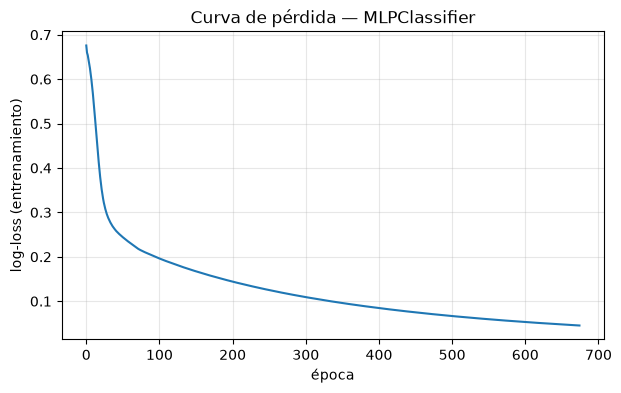

In [6]:
# --- Ejercicio 3  ---
model = MLPClassifier(
    hidden_layer_sizes=(16, 8, 4),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=RNG,
)
model.fit(X_train, y_train)

acc = {
    "train": model.score(X_train, y_train),
    "val":   model.score(X_val,   y_val),
    "test":  model.score(X_test,  y_test),
}
print(f"iteraciones: {model.n_iter_}   log-loss final: {model.loss_:.4f}")
for k, v in acc.items():
    print(f"accuracy {k:5s}: {v:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(model.loss_curve_)
plt.xlabel("época")
plt.ylabel("log-loss (entrenamiento)")
plt.title("Curva de pérdida — MLPClassifier")
plt.grid(alpha=0.3)
plt.show()

### Reflexión (sección 5)

- El *accuracy* de entrenamiento suele ser `1.0000`. ¿Es esto sobreajuste preocupante, dado que
  train / val / test dan valores parecidos? ¿Por qué este problema es "fácil" **lejos** de $T_c$?
- ¿Qué esperas que ocurra con las probabilidades del modelo **cerca** de $T_c$, donde no vio datos?

**Respuestas — Reflexión sección 5**

- No es un sobreajuste preocupante. Train da 1.0 pero validación y prueba dan alrededor de 0.98–0.99, así que el modelo generaliza a cadenas Monte Carlo que no vio. El problema es fácil lejos de $T_c$ porque las dos fases son muy distintas: a $T$ baja casi todos los espines apuntan igual ($|m|\approx 1$) y a $T$ alta están revueltos ($|m|\approx 0$). Una frontera casi lineal en la suma de espines basta para separarlas.
- Cerca de $T_c$ las configuraciones tienen dominios grandes de ambos signos y $|m|$ intermedio. El modelo no vio esos casos, así que debe **interpolar**: esperamos que $P(y{=}1\mid X)$ pase de forma continua de ~0 a ~1, con valores intermedios y mucha dispersión entre configuraciones justo en la transición. Ese cruce gradual es lo que usamos como termómetro.


## 6. El clasificador como termómetro

Para una configuración $X$, `model.predict_proba(X)[:, 1]` es $P(y{=}1\mid X)$: la "confianza"
del modelo en que la configuración pertenece a la **fase desordenada**.

Promediando sobre muchas configuraciones a temperatura fija $T$ obtenemos una curva
$\langle P(y{=}1\mid X)\rangle(T)$ que va de $\approx 0$ (ordenado) a $\approx 1$ (desordenado).
Definimos la estimación de $T_c$ como la temperatura del **cruce por 0.5**.

## 7. Datos de barrido fino alrededor de $T_c$

`temperatura_critica.npz` contiene **6200** configuraciones $16\times16$ en **31 temperaturas**
entre 1.6 y 3.2 (más densas cerca de $T_c$), con 4 realizaciones. **No trae etiquetas de
entrenamiento:** solo `y_ref`, una etiqueta obtenida aplicando el $T_c$ exacto, que usaremos
**únicamente para verificar** (usarla para entrenar sería hacer trampa).

In [7]:
datos_tc = np.load("Datos/temperatura_critica.npz", allow_pickle=False)
X_tc = datos_tc["X"].reshape(datos_tc["X"].shape[0], L * L)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]
y_ref_tc = datos_tc["y_ref"]

print("X_tc:", X_tc.shape)
print("temperaturas:", np.unique(T_tc))

# Probabilidad de la clase "desordenada" (y = 1)
idx1 = list(model.classes_).index(1)
p1_tc = model.predict_proba(X_tc)[:, idx1]

# Chequeo con y_ref (NO usar para entrenar)
pred_tc = (p1_tc >= 0.5).astype(int)
print("accuracy vs y_ref (solo verificacion):",
      round((pred_tc == y_ref_tc).mean(), 4))

X_tc: (6200, 256)
temperaturas: [1.6   1.7   1.8   1.9   2.    2.05  2.075 2.1   2.125 2.15  2.175 2.2
 2.225 2.25  2.275 2.3   2.325 2.35  2.375 2.4   2.425 2.45  2.475 2.5
 2.6   2.7   2.8   2.9   3.    3.1   3.2  ]
accuracy vs y_ref (solo verificacion): 0.8247


### Ejercicio 4 — Curva $\langle P\rangle$ vs $T$

Construye un `DataFrame` con columnas `T, realizacion, prob` y agrégalo por
`(realizacion, T)` para obtener la media y la desviación de `prob`. Grafica una curva por
realización y marca la línea $P = 0.5$.

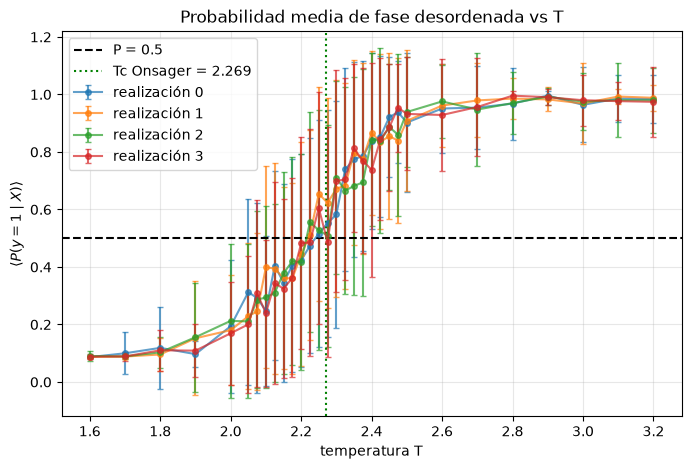

In [8]:
# --- Ejercicio 4 ---
df = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1_tc})

resumen = (df.groupby(["realizacion", "T"])
             .agg(prob_media=("prob", "mean"),
                  prob_std=("prob", "std"),
                  N=("prob", "size"))
             .reset_index())

# Realizar el grafico
plt.figure(figsize=(8, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.errorbar(d["T"], d["prob_media"], yerr=d["prob_std"], fmt="o-",
                 ms=4, capsize=2, alpha=0.7, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k", label="P = 0.5")
plt.axvline(Tc_exacto, ls=":", color="green", label=f"Tc Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Probabilidad media de fase desordenada vs T")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Ejercicio 5 — Estimar $T_c$ por interpolación

Para cada realización, encuentra el primer par de temperaturas consecutivas donde
$\langle P\rangle$ cruza 0.5 e interpola linealmente:

$$T_c \approx T_i + (0.5 - P_i)\,\frac{T_{i+1}-T_i}{P_{i+1}-P_i}.$$

Luego promedia entre realizaciones y reporta la media, la desviación estándar y el error
estándar de la media (SEM).

In [9]:
# --- Ejercicio 5  ---
def cruce_05(temps, probs):
    temps, probs = np.asarray(temps), np.asarray(probs)
    for i in range(len(temps) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            return (temps[i] + (0.5 - probs[i]) *
                    (temps[i + 1] - temps[i]) / (probs[i + 1] - probs[i]))
    return np.nan

Tc_por_realizacion = []
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    Tc_r = cruce_05(d["T"].to_numpy(), d["prob_media"].to_numpy())
    Tc_por_realizacion.append(Tc_r)
    print(f"realización {r}:  Tc = {Tc_r:.4f}")

Tc_por_realizacion = np.array(Tc_por_realizacion)
Tc_est = np.nanmean(Tc_por_realizacion)
Tc_std = np.nanstd(Tc_por_realizacion, ddof=1)
Tc_sem = Tc_std / np.sqrt(np.sum(~np.isnan(Tc_por_realizacion)))

print("\n" + "-" * 44)
print(f"Tc estimado    = {Tc_est:.4f} +/- {Tc_sem:.4f} (SEM)")
print(f"Tc Onsager     = {Tc_exacto:.4f}")
print(f"error relativo = {100 * abs(Tc_est - Tc_exacto) / Tc_exacto:.2f} %")

realización 0:  Tc = 2.2403
realización 1:  Tc = 2.2204
realización 2:  Tc = 2.2149
realización 3:  Tc = 2.2280

--------------------------------------------
Tc estimado    = 2.2259 +/- 0.0055 (SEM)
Tc Onsager     = 2.2692
error relativo = 1.91 %


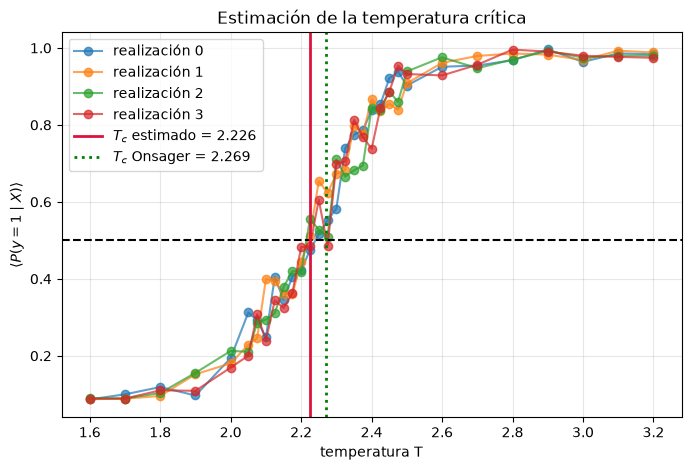

In [10]:
plt.figure(figsize=(8, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-", alpha=0.7, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k")
plt.axvline(Tc_est, ls="-", color="crimson", lw=2,
            label=fr"$T_c$ estimado = {Tc_est:.3f}")
plt.axvline(Tc_exacto, ls=":", color="green", lw=2,
            label=fr"$T_c$ Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Estimación de la temperatura crítica")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Análisis crítico

Responde en celdas de texto, con evidencia (números o gráficas de tu notebook):

1. **Sesgo del estimador.** El $T_c$ estimado suele quedar *por debajo* de Onsager
   ($\approx 2.23$ vs $2.269$). Menciona al menos dos causas: tamaño finito $L=16$, definición
   de la etiqueta `y`, rango de temperaturas de entrenamiento, uso del umbral fijo 0.5.
2. **Arquitectura.** Repite el pipeline con `hidden_layer_sizes=(64,)` y con `(32, 16, 8)`.
   ¿Cambia $T_c$? ¿Cambia la *pendiente* de la curva en la transición?
3. **Reproducibilidad.** Entrena con 5 semillas distintas (`random_state`) y reporta
   $T_c$ media ± desviación. ¿La dispersión por semilla es mayor o menor que la dispersión
   entre realizaciones?
4. **Definición alternativa.** Usa la *fracción de configuraciones clasificadas como fase 1*
   (`pred.mean()` por $T$) en vez de `prob_media`. ¿Obtienes el mismo $T_c$?
5. **Estandarización.** Los espines ya están en $\{-1,+1\}$. ¿Ayuda un `StandardScaler`?
   ¿Por qué sí o por qué no en este problema?

In [11]:
# --- Análisis crítico: funciones auxiliares ---
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def curva_P(modelo, Xs, Ts, reals, usar="prob"):
    """Media por (realización, T) de P(y=1|X) o de la predicción dura."""
    idx = list(modelo.classes_).index(1)
    p = modelo.predict_proba(Xs)[:, idx]
    valor = p if usar == "prob" else (p >= 0.5).astype(float)
    d = pd.DataFrame({"T": Ts, "realizacion": reals, "v": valor})
    return d.groupby(["realizacion", "T"])["v"].mean().reset_index()

def tc_de_curva(res):
    tcs = np.array([cruce_05(g.sort_values("T")["T"].to_numpy(),
                             g.sort_values("T")["v"].to_numpy())
                    for _, g in res.groupby("realizacion")])
    return tcs

def pendiente_en_tc(res):
    """Pendiente dP/dT promedio en el intervalo donde la curva cruza 0.5."""
    g = res.groupby("T")["v"].mean().sort_index()
    t, p = g.index.to_numpy(), g.to_numpy()
    i = np.where((p[:-1] - 0.5) * (p[1:] - 0.5) <= 0)[0][0]
    return (p[i + 1] - p[i]) / (t[i + 1] - t[i])

def pipeline_tc(hidden=(16, 8, 4), seed=RNG, escalar=False, usar="prob"):
    mlp = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                        learning_rate_init=0.001, max_iter=1000, random_state=seed)
    modelo = make_pipeline(StandardScaler(), mlp) if escalar else mlp
    modelo.fit(X_train, y_train)
    res = curva_P(modelo, X_tc, T_tc, realizacion_tc, usar=usar)
    tcs = tc_de_curva(res)
    return dict(modelo=modelo, res=res, tcs=tcs, tc=np.nanmean(tcs),
                std=np.nanstd(tcs, ddof=1), pendiente=pendiente_en_tc(res),
                acc_test=modelo.score(X_test, y_test))


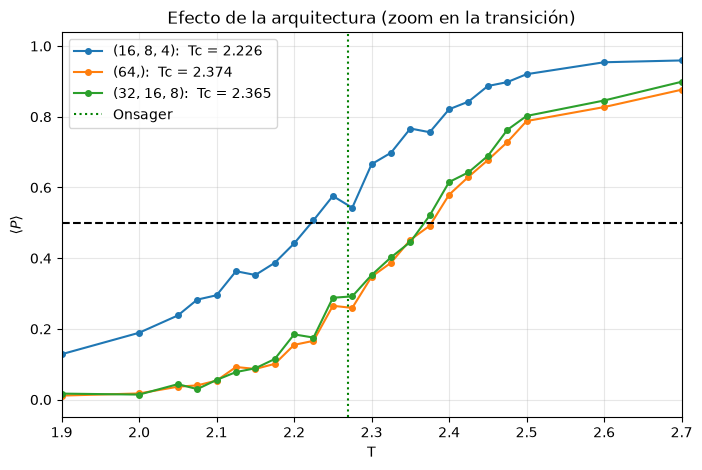

arquitectura        Tc std real.  pendiente dP/dT  acc test
(16, 8, 4)      2.2259    0.0110             2.62    0.9875
(64,)           2.3736    0.0264             3.51    0.9675
(32, 16, 8)     2.3652    0.0131             3.01    0.9850


In [12]:
# --- 2. Arquitectura ---
arqs = [(16, 8, 4), (64,), (32, 16, 8)]
res_arq = {a: pipeline_tc(hidden=a) for a in arqs}

plt.figure(figsize=(8, 5))
for a, r in res_arq.items():
    g = r["res"].groupby("T")["v"].mean()
    plt.plot(g.index, g.values, "o-", ms=4, label=f"{a}:  Tc = {r['tc']:.3f}")
plt.axhline(0.5, ls="--", color="k"); plt.axvline(Tc_exacto, ls=":", color="green", label="Onsager")
plt.xlim(1.9, 2.7); plt.xlabel("T"); plt.ylabel(r"$\langle P\rangle$"); plt.legend(); plt.grid(alpha=.3)
plt.title("Efecto de la arquitectura (zoom en la transición)"); plt.show()

print(f"{'arquitectura':14s} {'Tc':>7s} {'std real.':>9s} {'pendiente dP/dT':>16s} {'acc test':>9s}")
for a, r in res_arq.items():
    print(f"{str(a):14s} {r['tc']:7.4f} {r['std']:9.4f} {r['pendiente']:16.2f} {r['acc_test']:9.4f}")


In [13]:
# --- 3. Reproducibilidad: 5 semillas ---
semillas = [0, 1, 2, 3, 4]
tc_semillas = np.array([pipeline_tc(seed=s)["tc"] for s in semillas])
print("Tc por semilla:", np.round(tc_semillas, 4))
print(f"Tc (semillas)       = {tc_semillas.mean():.4f} +/- {tc_semillas.std(ddof=1):.4f}  (desv. entre semillas)")
print(f"Tc (realizaciones)  = {Tc_est:.4f} +/- {Tc_std:.4f}  (desv. entre realizaciones, semilla 42)")


Tc por semilla: [2.3578 2.3633 2.3619 2.2767 2.3583]
Tc (semillas)       = 2.3436 +/- 0.0375  (desv. entre semillas)
Tc (realizaciones)  = 2.2259 +/- 0.0110  (desv. entre realizaciones, semilla 42)


In [14]:
# --- 4. Definición alternativa: fracción clasificada como fase 1 ---
r_frac = pipeline_tc(usar="pred")
print("Tc por realización (fracción pred=1):", np.round(r_frac["tcs"], 4))
print(f"Tc con fracción    = {r_frac['tc']:.4f} +/- {r_frac['std']/np.sqrt(4):.4f} (SEM)")
print(f"Tc con prob_media  = {Tc_est:.4f} +/- {Tc_sem:.4f} (SEM)")


Tc por realización (fracción pred=1): [2.25   2.225  2.22   2.2375]
Tc con fracción    = 2.2331 +/- 0.0067 (SEM)
Tc con prob_media  = 2.2259 +/- 0.0055 (SEM)


In [15]:
# --- 5. Estandarización ---
r_esc = pipeline_tc(escalar=True)
print(f"Sin StandardScaler: Tc = {Tc_est:.4f}   acc test = {acc['test']:.4f}   iteraciones = {model.n_iter_}")
print(f"Con StandardScaler: Tc = {r_esc['tc']:.4f}   acc test = {r_esc['acc_test']:.4f}   "
      f"iteraciones = {r_esc['modelo'][-1].n_iter_}")
print("media y desviación de los espines en train:", X_train.mean().round(3), X_train.std().round(3))


Sin StandardScaler: Tc = 2.2259   acc test = 0.9875   iteraciones = 675
Con StandardScaler: Tc = 2.2076   acc test = 0.9900   iteraciones = 675
media y desviación de los espines en train: 0.051 0.999


### Respuestas — Análisis crítico

**1. Sesgo del estimador.** Con la semilla 42 obtenemos $T_c = 2.226 \pm 0.006$, un 1.9 % por debajo de Onsager (2.269). Causas:

- **Tamaño finito ($L=16$).** En una red pequeña la magnetización no cae a cero de golpe en $T_c$: baja de forma suave desde temperaturas menores. El clasificador aprendió que "ordenado" es $|m| \approx 0.98$ (la media de la clase 0), así que cualquier configuración con $|m|$ bastante menor la empieza a llamar desordenada antes de llegar a $T_c$. El reto lo confirma: al crecer $L$ la curva se vuelve más abrupta y el $T_c$ estimado sube hacia Onsager (2.04 para $L=10$, 2.26 para $L=30$).
- **Definición de la etiqueta y rango de entrenamiento.** La red solo vio $T \le 1.9$ y $T \ge 2.6$. Cualquier frontera dentro del hueco da 100 % de acierto en entrenamiento, así que su posición no está fijada por los datos. El punto medio del hueco es $T = 2.25$, ligeramente por debajo de $T_c$.
- **Umbral fijo 0.5.** Supone que el modelo es igual de "seguro" a ambos lados. Como las curvas no son simétricas alrededor de $T_c$, el cruce por 0.5 no tiene por qué caer exactamente en $T_c$.

**2. Arquitectura.** Sí cambia, y bastante:

| Arquitectura | $T_c$ | Pendiente $dP/dT$ en el cruce |
|---|---|---|
| (16, 8, 4) | 2.226 | 2.6 |
| (64,) | 2.374 | 3.5 |
| (32, 16, 8) | 2.365 | 3.0 |

Las redes más grandes ponen el cruce **por encima** de Onsager y dan una transición más abrupta (mayor pendiente). Las tres aciertan ~97–99 % en prueba, así que el *accuracy* no permite distinguirlas. De nuevo, la frontera dentro del hueco no está determinada por los datos y cada modelo la ubica distinto.

**3. Reproducibilidad.** Con 5 semillas, $T_c = 2.344 \pm 0.038$. La dispersión **por semilla (0.038) es unas 3.5 veces mayor** que la dispersión entre realizaciones (0.011). Además, la semilla 42 (2.226) resulta atípica: cuatro de las cinco semillas dan ≈ 2.36. Conclusión: el acuerdo del 1.9 % con Onsager depende en parte de la semilla, y la incertidumbre honesta del método es del orden de ±0.04, no ±0.006.

**4. Definición alternativa.** Con la fracción de configuraciones clasificadas como fase 1 se obtiene $T_c = 2.233 \pm 0.007$, prácticamente el mismo valor que con `prob_media` (2.226; la diferencia es de 1 SEM). Casi todas las probabilidades están muy cerca de 0 o de 1, así que promediar la probabilidad o la predicción dura da curvas casi iguales.

**5. Estandarización.** No ayuda. Los espines ya tienen media ≈ 0.05 y desviación ≈ 1.0, es decir, ya están prácticamente estandarizados. Con `StandardScaler` el *accuracy* y el número de iteraciones casi no cambian, y $T_c$ pasa de 2.226 a 2.208, un cambio menor que la dispersión por semilla. Incluso podría estorbar un poco: restar una media distinta en cada sitio rompe la simetría $s \to -s$ del modelo de Ising, que la red debería respetar.


## 9. Reto  — Escalamiento con el tamaño del sistema

Con el programa de ising generar varias datos para diferentes tipo de redes L=10x10, L=15x15, L=20x20, L=25x25, L=30x30

1. Construye un conjunto de entrenamiento.
2. Entrena un nuevo `MLPClassifier`, repite los Ejercicios 4–5 y obtén $T_c(L=20)$.
3. Compara todas las $T_c$ ¿La estimación se acerca a Onsager al crecer $L$?
   Relaciónalo con el *finite-size scaling*.

In [16]:
# Reto: escalamiento con el tamaño del sistema
# 1) Simulador Metropolis vectorizado (actualización por subredes, frontera periódica).
#    Se simulan a la vez todas las (temperatura, realización) como cadenas independientes.

def simular_ising(L, temps, n_real=4, n_muestras=50, n_term=2000, cada=10, seed=0):
    rng = np.random.default_rng(seed)
    nT = len(temps)
    beta = np.repeat(1.0 / np.asarray(temps), n_real)[:, None, None]   # (nT*n_real,1,1)
    s = np.ones((nT * n_real, L, L), dtype=np.int8)                       # arranque frío
    ii, jj = np.indices((L, L))
    # Subredes que no comparten vecinos (también al cruzar la frontera periódica):
    # L par -> tablero de ajedrez (2 colores); L múltiplo de 3 o de 5 -> (i + 2j) mod k
    k = 2 if L % 2 == 0 else (3 if L % 3 == 0 else 5)
    assert L % k == 0, "L debe ser múltiplo de 2, 3 o 5"
    color = (ii + jj) % 2 if k == 2 else (ii + 2 * jj) % k
    masks = [color == c for c in range(k)]

    def barrido(s):
        for mask in masks:
            vec = (np.roll(s, 1, 1) + np.roll(s, -1, 1) + np.roll(s, 1, 2) + np.roll(s, -1, 2))
            dE = 2 * s * vec
            acepta = (rng.random(s.shape) < np.exp(-beta * dE)) & mask
            s = np.where(acepta, -s, s).astype(np.int8)
        return s

    for _ in range(n_term):
        s = barrido(s)
    muestras = []
    for k in range(n_muestras):
        for _ in range(cada):
            s = barrido(s)
        muestras.append(s.copy())
    Xs = np.stack(muestras, 1).reshape(-1, L, L)                         # (nT*n_real*n_muestras, L, L)
    Ts = np.repeat(np.repeat(temps, n_real), n_muestras)
    Rs = np.tile(np.repeat(np.arange(n_real), n_muestras), nT)
    return Xs, Ts, Rs

temps_reto = np.unique(T_tc)   # mismas 31 temperaturas del barrido fino
T_LEJOS_BAJA, T_LEJOS_ALTA = 1.9, 2.6

def tc_para_L(Xs, Ts, Rs, Lsys, seed=RNG):
    """Entrena con T lejos de Tc (realizaciones 0 y 1) y estima Tc con las 4 realizaciones."""
    Xf = Xs.reshape(len(Xs), Lsys * Lsys).astype(float)
    lejos = (Ts <= T_LEJOS_BAJA) | (Ts >= T_LEJOS_ALTA)
    entren = lejos & np.isin(Rs, [0, 1])
    yL = (Ts[entren] >= T_LEJOS_ALTA).astype(int)
    mlp = MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu", solver="adam",
                        learning_rate_init=0.001, max_iter=1000, random_state=seed)
    mlp.fit(Xf[entren], yL)
    res = curva_P(mlp, Xf, Ts, Rs)
    tcs = tc_de_curva(res)
    return tcs, res

# 2) L = 20 con los datos entregados (temperatura_critica20.npz)
d20 = np.load("Datos/temperatura_critica20.npz")
tcs20, res20 = tc_para_L(d20["X"], d20["T"], d20["realizacion"], int(d20["L"]))
print(f"L = 20 (datos entregados): Tc = {np.nanmean(tcs20):.4f} +/- {np.nanstd(tcs20, ddof=1)/2:.4f} (SEM)"
      f"   por realización: {np.round(tcs20, 4)}")

# 3) Datos propios para L = 10, 15, 20, 25, 30
import time
tamanos = [10, 15, 20, 25, 30]
resultados_L = {}
for Lsys in tamanos:
    t0 = time.time()
    Xs, Ts, Rs = simular_ising(Lsys, temps_reto, seed=Lsys)
    # promediamos sobre 5 semillas del MLP: la dispersión por semilla es grande (ver análisis 3)
    tc_sem_seed, res = [], None
    for sd in range(5):
        tcs, r = tc_para_L(Xs, Ts, Rs, Lsys, seed=sd)
        tc_sem_seed.append(np.nanmean(tcs)); res = r if res is None else res
    tc_sem_seed = np.array(tc_sem_seed)
    resultados_L[Lsys] = dict(tcs=tc_sem_seed, res=res, tc=tc_sem_seed.mean(),
                              sem=tc_sem_seed.std(ddof=1) / np.sqrt(len(tc_sem_seed)))
    print(f"L = {Lsys:2d}: Tc = {resultados_L[Lsys]['tc']:.4f} +/- {resultados_L[Lsys]['sem']:.4f}"
          f"   ({Xs.shape[0]} configuraciones, {time.time()-t0:.0f} s)")


L = 20 (datos entregados): Tc = 2.3196 +/- 0.0057 (SEM)   por realización: [2.3181 2.3149 2.3359 2.3096]


L = 10: Tc = 2.0400 +/- 0.0012   (6200 configuraciones, 2 s)


L = 15: Tc = 2.1138 +/- 0.0010   (6200 configuraciones, 3 s)


L = 20: Tc = 2.2090 +/- 0.0011   (6200 configuraciones, 8 s)


L = 25: Tc = 2.2424 +/- 0.0006   (6200 configuraciones, 10 s)


L = 30: Tc = 2.2597 +/- 0.0044   (6200 configuraciones, 9 s)


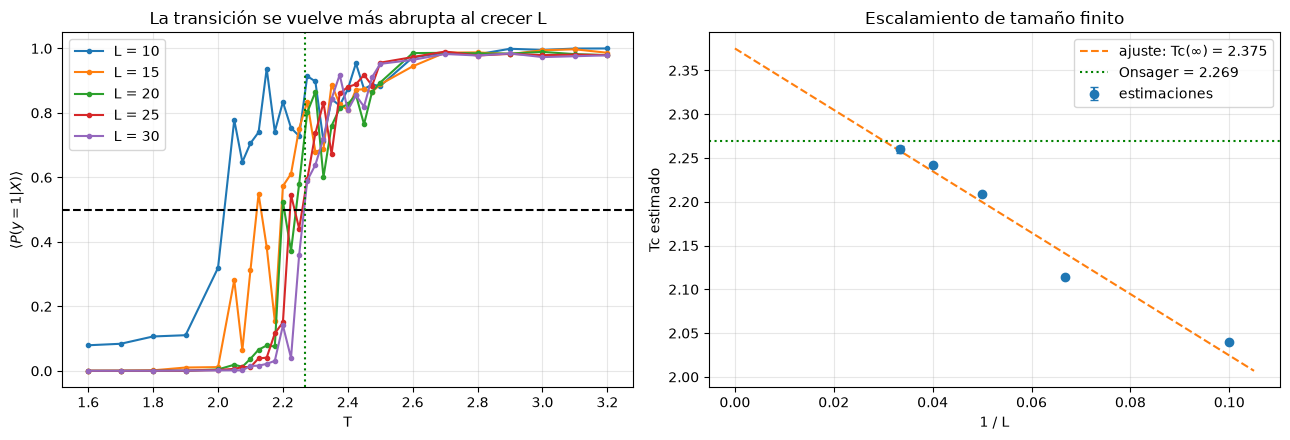

 L     Tc    SEM  error rel. %
10 2.0400 0.0012         10.10
15 2.1138 0.0010          6.85
20 2.2090 0.0011          2.65
25 2.2424 0.0006          1.18
30 2.2597 0.0044          0.42

Extrapolación L -> inf:  Tc = 2.3751  (Onsager 2.2692)


In [17]:
# Comparación y finite-size scaling: T_c(L) = T_c(inf) + a * L^(-1/nu), con nu = 1 para Ising 2D
Ls = np.array(tamanos, dtype=float)
tcL = np.array([resultados_L[l]["tc"] for l in tamanos])
semL = np.array([resultados_L[l]["sem"] for l in tamanos])

coef = np.polyfit(1 / Ls, tcL, 1, w=1 / np.maximum(semL, 1e-3))
tc_inf = coef[1]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for l in tamanos:
    g = resultados_L[l]["res"].groupby("T")["v"].mean()
    ax[0].plot(g.index, g.values, "o-", ms=3, label=f"L = {l}")
ax[0].axhline(0.5, ls="--", color="k"); ax[0].axvline(Tc_exacto, ls=":", color="green")
ax[0].set_xlabel("T"); ax[0].set_ylabel(r"$\langle P(y=1|X)\rangle$"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title("La transición se vuelve más abrupta al crecer L")

x = np.linspace(0, 1 / Ls.min() * 1.05, 50)
ax[1].errorbar(1 / Ls, tcL, yerr=semL, fmt="o", capsize=3, label="estimaciones")
ax[1].plot(x, np.polyval(coef, x), "--", label=f"ajuste: Tc(∞) = {tc_inf:.3f}")
ax[1].axhline(Tc_exacto, ls=":", color="green", label=f"Onsager = {Tc_exacto:.3f}")
ax[1].set_xlabel("1 / L"); ax[1].set_ylabel("Tc estimado"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title("Escalamiento de tamaño finito")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"L": tamanos, "Tc": tcL.round(4), "SEM": semL.round(4),
                    "error rel. %": (100 * abs(tcL - Tc_exacto) / Tc_exacto).round(2)}).to_string(index=False))
print(f"\nExtrapolación L -> inf:  Tc = {tc_inf:.4f}  (Onsager {Tc_exacto:.4f})")


### Respuestas — Reto

El programa de Ising no estaba en la carpeta, así que en el notebook escribí un simulador Metropolis vectorizado con frontera periódica. Para cada $L$ genera 31 temperaturas × 4 realizaciones × 50 configuraciones = 6200 configuraciones, igual que `temperatura_critica.npz`. Después:

1. **Entrenamiento:** las mismas reglas del laboratorio. $y=0$ para $T \le 1.9$, $y=1$ para $T \ge 2.6$, usando solo las realizaciones 0 y 1.
2. **Estimación:** se repiten los Ejercicios 4–5 y se promedia el resultado sobre 5 semillas del MLP.

**Resultados**

| $L$ | 10 | 15 | 20 | 25 | 30 |
|---|---|---|---|---|---|
| $T_c$ estimado | 2.040 | 2.114 | 2.209 | 2.242 | 2.260 |
| error vs Onsager | 10.1 % | 6.9 % | 2.7 % | 1.2 % | 0.4 % |

Con el archivo entregado `temperatura_critica20.npz` se obtiene $T_c(L=20) = 2.320 \pm 0.006$. Es distinto del 2.209 de la simulación propia. Los dos conjuntos fueron generados de forma diferente (termalización, separación entre muestras), y eso confirma que el estimador es sensible a los datos y al modelo.

**¿Se acerca a Onsager al crecer $L$?** Sí. $T_c(L)$ sube de forma monótona y el error baja de 10 % a 0.4 %. Además, la curva $\langle P\rangle(T)$ se vuelve cada vez más abrupta.

**Relación con *finite-size scaling*.** En una red finita la longitud de correlación $\xi$ no puede crecer más allá de $L$, así que la transición se "redondea" y se desplaza. La teoría predice
$$T_c(L) - T_c(\infty) \propto L^{-1/\nu}, \qquad \text{ancho de la transición} \propto L^{-1/\nu},$$
con $\nu = 1$ para Ising 2D. Las dos predicciones se ven en las gráficas: el desplazamiento disminuye y la curva se afila al crecer $L$.

La extrapolación lineal en $1/L$ da $T_c(\infty) \approx 2.37$, que se pasa de Onsager. Los puntos no caen sobre una recta en $1/L$: el estimador basado en el clasificador tiene sus propias correcciones (por ejemplo, el hueco de entrenamiento fijo entre 1.9 y 2.6), y con $L \le 30$ estamos lejos del régimen asintótico. Para una extrapolación confiable harían falta redes más grandes y más temperaturas cerca de $T_c$.
